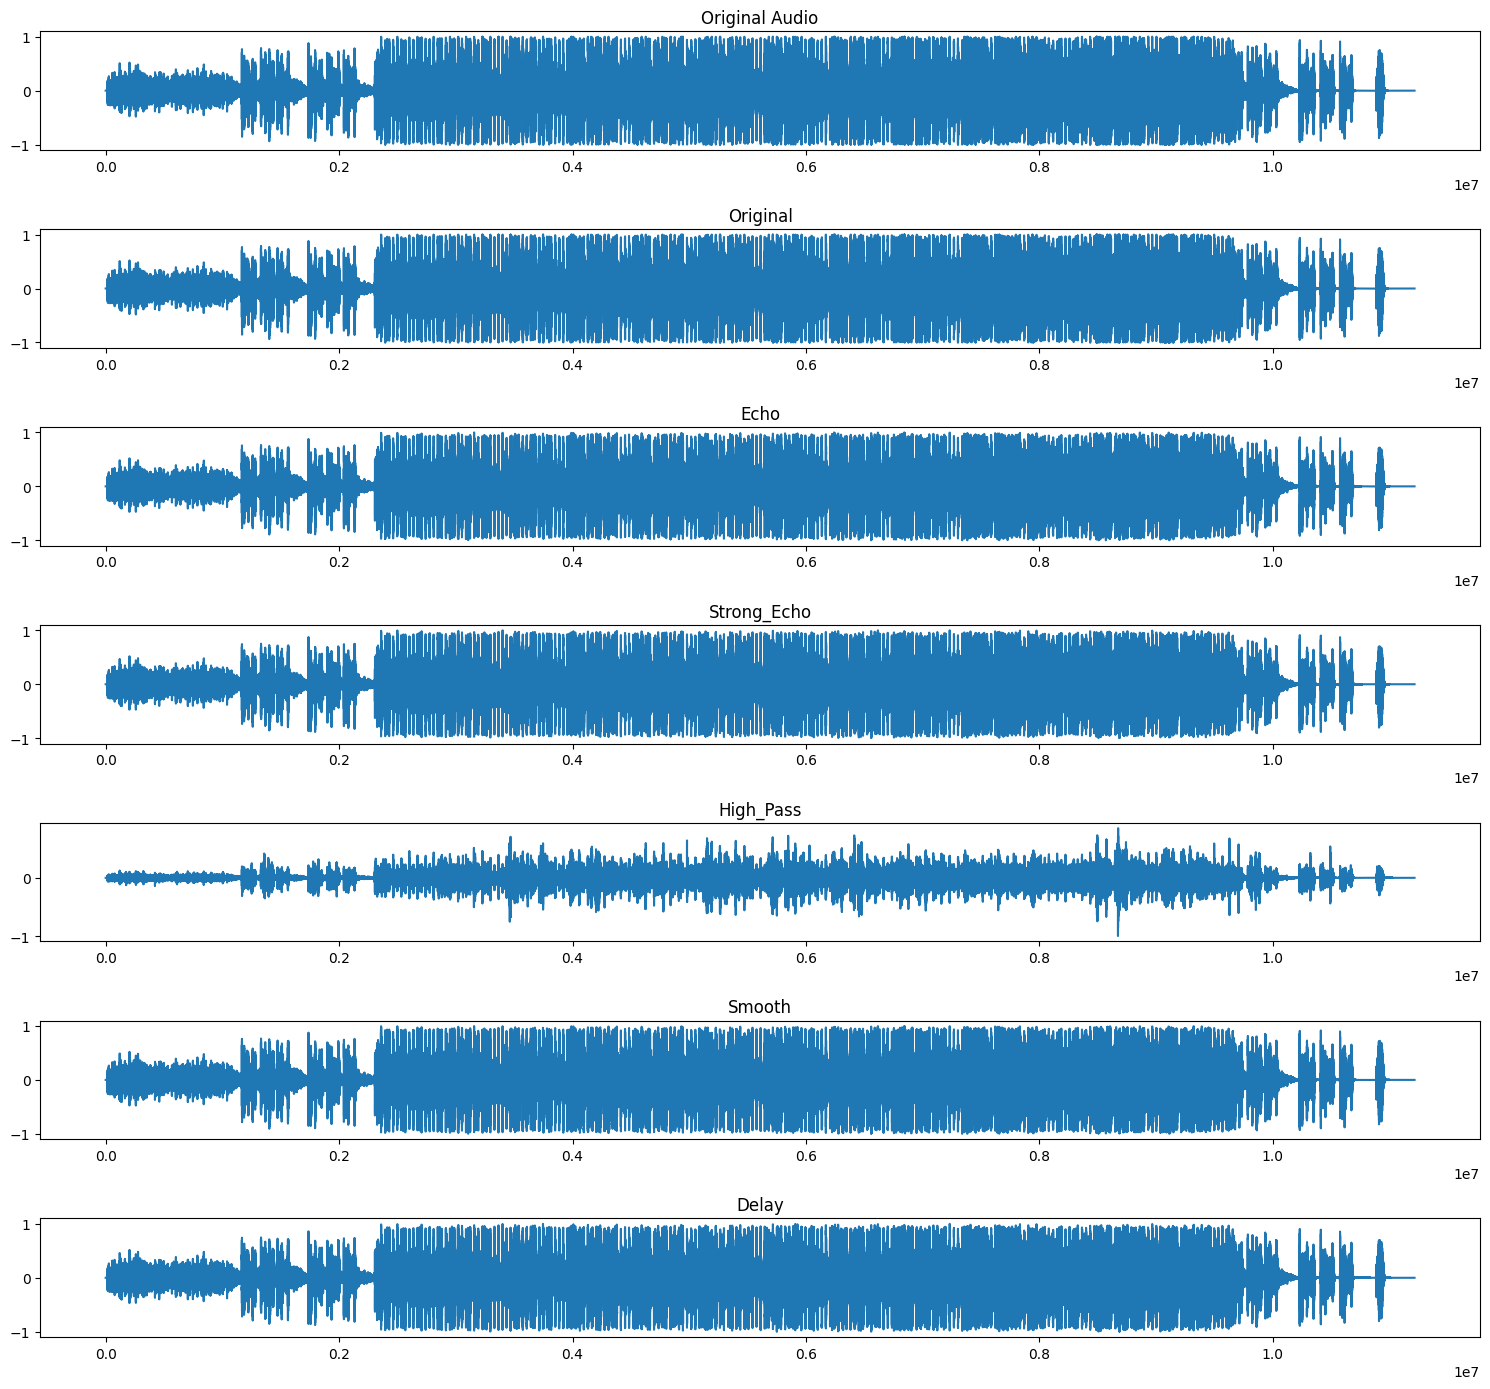

Processing Completed Successfully


In [1]:
from pydub import AudioSegment
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve, lfilter

# -----------------------------
# Load Audio File
# -----------------------------
audio = AudioSegment.from_mp3("original.mp3")

# Convert to Mono
audio = audio.set_channels(1)

# Extract Samples
samples = np.array(
    audio.get_array_of_samples(),
    dtype=np.float32
)

# Normalize
samples = samples / np.max(np.abs(samples))

# -----------------------------
# Define Different Impulse Responses
# -----------------------------
kernels = {
    "Original": np.array([1], dtype=np.float32),

    "Echo": np.array([1, 0, 0.6], dtype=np.float32),

    "Strong_Echo": np.array(
        [1, 0, 0, 0.4, 0.2],
        dtype=np.float32
    ),

    "High_Pass": np.array([1, -0.8], dtype=np.float32),

    "Smooth": np.array(
        [0.1, 0.3, 0.4, 0.2],
        dtype=np.float32
    ),

    "Delay": np.array(
        [1, 0, 0, 0, 0.7],
        dtype=np.float32
    )
}

# -----------------------------
# Plot Original and Filtered Signals
# -----------------------------
plt.figure(figsize=(15, 14))

# Original Audio
plt.subplot(len(kernels) + 1, 1, 1)
plt.plot(samples)
plt.title("Original Audio")

count = 2

# -----------------------------
# Apply Convolution
# -----------------------------
for name, kernel in kernels.items():

    output = convolve(samples, kernel, mode="same")

    # Normalize output
    output = output / np.max(np.abs(output))

    # Plot output
    plt.subplot(len(kernels) + 1, 1, count)
    plt.plot(output)
    plt.title(name)

    # Convert to 16-bit audio
    output_int16 = (output * 32767).astype(np.int16)

    # Create audio segment
    new_audio = AudioSegment(
        output_int16.tobytes(),
        frame_rate=audio.frame_rate,
        sample_width=2,
        channels=1
    )

    # Save audio
    new_audio.export(
        f"{name}.wav",
        format="wav"
    )

    count += 1

# -----------------------------
# Inverse Filtering
# -----------------------------
inverse_kernel = np.array(
    [1, -0.4, 0.16, -0.064],
    dtype=np.float32
)

inverse = lfilter(
    inverse_kernel,
    [1],
    samples
)

# Normalize inverse output
inverse = inverse / np.max(np.abs(inverse))

# Convert to 16-bit
inverse_int16 = (inverse * 32767).astype(np.int16)

# Create inverse audio
inverse_audio = AudioSegment(
    inverse_int16.tobytes(),
    frame_rate=audio.frame_rate,
    sample_width=2,
    channels=1
)

# Save inverse filtered audio
inverse_audio.export(
    "Inverse_Filter_Output.wav",
    format="wav"
)

# -----------------------------
# Display Graphs
# -----------------------------
plt.tight_layout()
plt.show()

print("Processing Completed Successfully")